# Lab: Implementing Transformers for Text Generation — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/03-keras-and-tensorflow/notebooks/lab-implementing-transformers-for-text-generation.ipynb) · [Course notes](../../../courses/03-keras-and-tensorflow/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations. Bundled TensorFlow datasets use 512 training / 256 test examples; fit inputs use at most 512 examples or eight dataset batches. For bounded text-generation verification, construct only the first 32 shifted token windows. Both sequence-length variants use this limit; the full Transformer architecture is retained.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader
import tensorflow as tf
tf.random.set_seed(42)
for _dataset in [tf.keras.datasets.mnist,tf.keras.datasets.fashion_mnist,tf.keras.datasets.cifar10]:
    _original_load = _dataset.load_data
    def _small_load(*args,_load=_original_load,**kwargs):
        (x,y),(xt,yt) = _load(*args,**kwargs)
        return (x[:512],y[:512]),(xt[:256],yt[:256])
    _dataset.load_data = _small_load
_keras_fit = tf.keras.Model.fit
def _small_fit(self,*args,**kwargs):
    args = list(args)
    def _limit(value):
        if isinstance(value,(np.ndarray,pd.DataFrame,pd.Series,tf.Tensor,tf.RaggedTensor)):return value[:512]
        if isinstance(value,(tuple,list)) and value and all(isinstance(x,(np.ndarray,tf.Tensor,tf.RaggedTensor)) for x in value):return type(value)(x[:512] for x in value)
        if isinstance(value,tf.data.Dataset):return value.take(8)
        return value
    for i in range(min(2,len(args))):args[i]=_limit(args[i])
    for key in ['x','y','validation_data']:
        if key in kwargs:kwargs[key]=_limit(kwargs[key])
    kwargs['epochs']=min(2,kwargs.get('epochs',2))
    data=args[0] if args else kwargs.get('x')
    if hasattr(data,'class_indices'):
        kwargs['steps_per_epoch']=min(2,len(data))
        if hasattr(kwargs.get('validation_data'),'class_indices'):
            kwargs['validation_steps']=min(2,len(kwargs['validation_data']))
    return _keras_fit(self,*args,**kwargs)
tf.keras.Model.fit = _small_fit


Matplotlib is building the font cache; this may take a moment.


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Lab: Implementing Transformers for Text Generation**


Estimated time needed: **30** minutes


In this lab, you will learn to implement Transformers for text generation tasks. 


## Learning Objectives

- Implement Transformers for text generation tasks 

- Build, train, and evaluate Transformer models for text generation using TensorFlow and Keras 

- Apply text generation in real-world scenarios 


----


### Step-by-step instructions 

#### Step 1: Set up the environment 

- Import necessary libraries and load the data set 

- Preprocess the dataset for training 

In the following code: 

- Import TensorFlow and other necessary libraries. 

- Load the Shakespeare text dataset. 

- Preprocess the data set using the TextVectorization layer to convert text into integer sequences. 


In [2]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.utils import get_file

In [3]:
path_to_file = get_file('shakespeare.txt', 'https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt')
text = open(path_to_file, 'rb').read().decode(encoding='utf-8')
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [4]:
vocab_size = 10000
seq_length = 100
vectorizer = TextVectorization(max_tokens=vocab_size, output_mode='int')
text_ds = tf.data.Dataset.from_tensor_slices([text]).batch(1)
vectorizer.adapt(text_ds)
vectorized_text = vectorizer([text])[0]
print('Vectorized text shape:', vectorized_text.shape)
print('First 10 vectorized tokens:', vectorized_text.numpy()[:10])

Vectorized text shape: (202646,)
First 10 vectorized tokens: [ 89 270 138  36 982 144 673 125  16 106]


2026-11-25 16:41:46.682465: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


#### Step 2: Create input and target sequences 

Generate input and target sequences for training the Transformer model. 

In the following code: 

- Define a function to generate input and target sequences. 

- Split the text data into sequences of the specified length. 

- Convert the sequences into TensorFlow tensors for training. 

Generative sequence: 


In [5]:
def create_sequences(text, seq_length):
    input_seqs = []
    target_seqs = []
    for i in range(min(32, len(text) - seq_length)):
        input_seq = text[i:i + seq_length]
        target_seq = text[i + 1:i + seq_length + 1]
        input_seqs.append(input_seq)
        target_seqs.append(target_seq)
    return (np.array(input_seqs), np.array(target_seqs))
X, Y = create_sequences(vectorized_text.numpy(), seq_length)
print('Number of sequences generated:', len(X))
print('Sample input sequence:', X[0] if len(X) > 0 else 'No sequences generated')
assert X.size > 0, 'Input data X is empty'
assert Y.size > 0, 'Target data Y is empty'
X = tf.convert_to_tensor(X)
Y = tf.convert_to_tensor(Y)
print('Shape of X:', X.shape)
print('Shape of Y:', Y.shape)

Number of sequences generated: 32
Sample input sequence: [  89  270  138   36  982  144  673  125   16  106   34  106  106   89
  270    7   41   34 1286  344    4  200   64    4 3690   34 1286 1286
   89  270   89    7   93 1187  225   12 2442  592    4    2  307   34
   36 2655   36 2655   89  270   72   79  506   27    3   56   24 1390
   57   40  161 2328  644    9 4980   34   32   54 2863  885   72   17
   18  163  146  146  165  270   74  218   46  595   89  270   36   41
 6739  172  595    2 1780   46   29 1323 5151   47   58 4151   79   39
   60   58]
Shape of X: (32, 100)
Shape of Y: (32, 100)


#### Step 3: Build the Transformer model 

Define the Transformer model architecture for text generation. 

In the following code: 

- Define the TransformerBlock class that includes multi-head attention and feedforward layers with normalization and dropout. 

- Define the TransformerModel class, including embedding, positional encoding, and multiple Transformer blocks. 

- Compile the Transformer model using the Adam optimizer and sparse categorical cross-entropy loss function. 

Transformer model: 


In [6]:
from tensorflow.keras.layers import Embedding, MultiHeadAttention, Dense, LayerNormalization, Dropout
from tensorflow.keras.models import Model

class TransformerBlock(tf.keras.layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super(TransformerBlock, self).__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([Dense(ff_dim, activation='relu'), Dense(embed_dim)])
        self.layernorm1 = LayerNormalization(epsilon=1e-06)
        self.layernorm2 = LayerNormalization(epsilon=1e-06)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=False):
        attn_output = self.att(inputs, inputs, use_causal_mask=True, training=training)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

class TransformerModel(Model):

    def __init__(self, vocab_size, embed_dim, num_heads, ff_dim, num_layers, seq_length):
        super(TransformerModel, self).__init__()
        self.embedding = Embedding(vocab_size, embed_dim)
        self.pos_encoding = self.positional_encoding(seq_length, embed_dim)
        self.transformer_blocks = [TransformerBlock(embed_dim, num_heads, ff_dim) for _ in range(num_layers)]
        self.dense = Dense(vocab_size)

    def positional_encoding(self, seq_length, embed_dim):
        angle_rads = self.get_angles(np.arange(seq_length)[:, np.newaxis], np.arange(embed_dim)[np.newaxis, :], embed_dim)
        angle_rads[:, 0::2] = np.sin(angle_rads[:, 0::2])
        angle_rads[:, 1::2] = np.cos(angle_rads[:, 1::2])
        pos_encoding = angle_rads[np.newaxis, ...]
        return tf.cast(pos_encoding, dtype=tf.float32)

    def get_angles(self, pos, i, embed_dim):
        angle_rates = 1 / np.power(10000, 2 * (i // 2) / np.float32(embed_dim))
        return pos * angle_rates

    def call(self, inputs, training=False):
        seq_len = tf.shape(inputs)[1]
        x = self.embedding(inputs)
        x += self.pos_encoding[:, :seq_len, :]
        for transformer_block in self.transformer_blocks:
            x = transformer_block(x, training=training)
        output = self.dense(x)
        return output

In [7]:
embed_dim = 256
num_heads = 4
ff_dim = 512
num_layers = 4
model = TransformerModel(vocab_size, embed_dim, num_heads, ff_dim, num_layers, seq_length)
_ = model(tf.random.uniform((1, seq_length), maxval=vocab_size, dtype=tf.int32))
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True))
model.summary()

Model: "transformer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (1, 100, 256)          │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_2             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_3             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (1, 100, 10000)        │     2,570,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,393,360 (39.65 MB)

 Trainable params: 10,393,360 (39.65 MB)

 Non-trainable params: 0 (0.00 B)

#### Step 4: Train the Transformer model 

Train the Transformer model on the preprocessed text data. 

In the following code: 

- Train the Transformer model on the input and target sequences 

- Plot the training loss to monitor the model's performance over epochs 

Model training: 


> #### Note: The original dataset is large, we have reduced it to 10,000 samples and limited the training to 2 epochs in order to minimize execution time


In [8]:
X = X[:10000]
Y = Y[:10000]

Epoch 1/2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - loss: 9.2747

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - loss: 9.2747


Epoch 2/2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 8.7454

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - loss: 8.7454


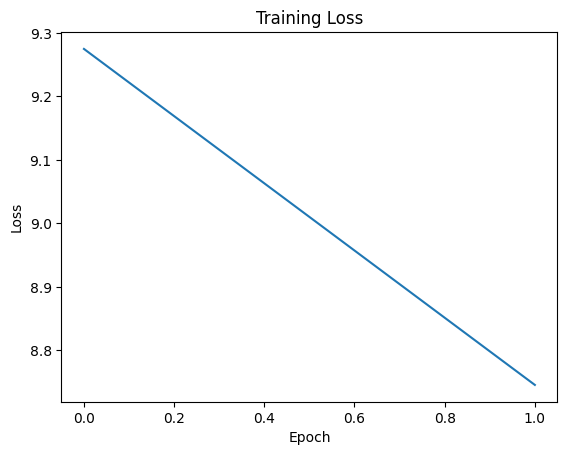

In [9]:
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='loss', patience=2, restore_best_weights=True)
history = model.fit(X, Y, epochs=2, batch_size=32, callbacks=[early_stopping])
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()

#### Step 5: Generate text with the trained model 

Define a function to generate text using the trained Transformer model. 

In the following code: 

- Define the generate_text function to generate text using the trained Transformer model 

- Convert the start string into numerical format 

- Use the model to predict the next word and append it to the generated text 

- Print the generated text 

#### Text generation: 


In [10]:
def generate_text(model, start_string, num_generate=100, temperature=1.0):
    input_eval = vectorizer([start_string]).numpy()
    if input_eval.shape[1] < seq_length:
        padding = np.zeros((1, seq_length - input_eval.shape[1]))
        input_eval = np.concatenate((padding, input_eval), axis=1)
    elif input_eval.shape[1] > seq_length:
        input_eval = input_eval[:, -seq_length:]
    input_eval = tf.convert_to_tensor(input_eval)
    text_generated = []
    for i in range(num_generate):
        predictions = model(input_eval, training=False)
        predictions = predictions[:, -1, :]
        predictions = predictions / temperature
        predicted_id = tf.random.categorical(predictions, num_samples=1)[0, 0].numpy()
        input_eval = np.append(input_eval.numpy(), [[predicted_id]], axis=1)
        input_eval = input_eval[:, -seq_length:]
        input_eval = tf.convert_to_tensor(input_eval)
        text_generated.append(vectorizer.get_vocabulary()[predicted_id])
    return start_string + ' ' + ' '.join(text_generated)
start_string = 'To be, or not to be'
generated_text = generate_text(model, start_string, temperature=0.7)
print(generated_text)

To be, or not to be walking oercome outstretchd quicken betters caparison simple devouring petruchio howld penitence xi strongframed matron repentant accomplish your frank overmuch praise superfluity harsh mistaenfor untie tos pirate unruly ready convenient outside overlook grows mannd gramercies virginity exercise curtains heap cushion raying numas oxlips storehouses lengththe am paying fond toe hereof falter rebate apology whereon leases living william score majesty tablebook valiantness longparted bred ball nodding loathes foreign persecutor snakes destroy promising placket pedant virginity bounds petitionary ransom kneel dissension opend wheresoeer rashlevied snow toad queeno pumps presuming wildgoose thirty advice execution doubts committed give tod cannibals affianced pluck sects groand stripling


### Practice exercises 

> ####  Note: Results may vary since the dataset size was reduced and training was limited to 2 epochs to shorten execution time. However, you are encouraged to experiment with different epoch values for deeper learning

### Exercise 1: Experiment with different sequence lengths 

**Objective:** Implement different sequence lengths to understand their effect on the performance of the Transformer model. 

**Instructions:**

- Change the sequence length to 50 

- Preprocess the data set with the new sequence length 

- Train the model and compare the training loss 


Vectorized text shape: (202646,)
First 10 vectorized tokens: [ 89 270 138  36 982 144 673 125  16 106]
Number of sequences generated: 32
Sample input sequence: [  89  270  138   36  982  144  673  125   16  106   34  106  106   89
  270    7   41   34 1286  344    4  200   64    4 3690   34 1286 1286
   89  270   89    7   93 1187  225   12 2442  592    4    2  307   34
   36 2655   36 2655   89  270   72   79]
Shape of X: (32, 50)
Shape of Y: (32, 50)


2026-11-25 16:42:00.984839: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Model: "transformer_model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (1, 50, 256)           │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_4             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_5             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_6             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_7             │ ?                      │     1,315,840 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (1, 50, 10000)         │     2,570,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,393,360 (39.65 MB)

 Trainable params: 10,393,360 (39.65 MB)

... (3 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - loss: 9.2467


Epoch 2/2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 8.6412

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 8.6412


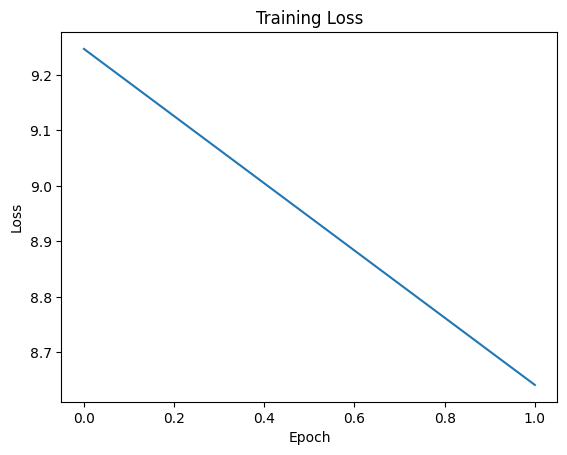

In [11]:
vocab_size = 10000
seq_length = 50
vectorizer = TextVectorization(max_tokens=vocab_size, output_mode='int')
text_ds = tf.data.Dataset.from_tensor_slices([text]).batch(1)
vectorizer.adapt(text_ds)
vectorized_text = vectorizer([text])[0]
print('Vectorized text shape:', vectorized_text.shape)
print('First 10 vectorized tokens:', vectorized_text.numpy()[:10])
X, Y = create_sequences(vectorized_text.numpy(), seq_length)
print('Number of sequences generated:', len(X))
print('Sample input sequence:', X[0] if len(X) > 0 else 'No sequences generated')
assert X.size > 0, 'Input data X is empty'
assert Y.size > 0, 'Target data Y is empty'
X = tf.convert_to_tensor(X)
Y = tf.convert_to_tensor(Y)
print('Shape of X:', X.shape)
print('Shape of Y:', Y.shape)
X = X[:10000]
Y = Y[:10000]
embed_dim = 256
num_heads = 4
ff_dim = 512
num_layers = 4
model = TransformerModel(vocab_size, embed_dim, num_heads, ff_dim, num_layers, seq_length)
_ = model(tf.random.uniform((1, seq_length), maxval=vocab_size, dtype=tf.int32))
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True))
model.summary()
early_stopping = EarlyStopping(monitor='loss', patience=2, restore_best_weights=True)
history = model.fit(X, Y, epochs=2, batch_size=32, callbacks=[early_stopping])
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python



# Preprocess the dataset 
vocab_size = 10000 
seq_length = 50 

# Adapt TextVectorization to full text 
vectorizer = TextVectorization(max_tokens=vocab_size, output_mode='int') 
text_ds = tf.data.Dataset.from_tensor_slices([text]).batch(1) 
vectorizer.adapt(text_ds) 

# Vectorize the text 
vectorized_text = vectorizer([text])[0] 
print("Vectorized text shape:", vectorized_text.shape) 
print("First 10 vectorized tokens:", vectorized_text.numpy()[:10]) 

X, Y = create_sequences(vectorized_text.numpy(), seq_length) 


# Check if sequences are correctly generated 
print("Number of sequences generated:", len(X)) 
print("Sample input sequence:", X[0] if len(X) > 0 else "No sequences generated") 

# Check if X and Y are not empty 
assert X.size > 0, "Input data X is empty" 
assert Y.size > 0, "Target data Y is empty" 
X = tf.convert_to_tensor(X) 
Y = tf.convert_to_tensor(Y) 
print("Shape of X:", X.shape) 
print("Shape of Y:", Y.shape)
X = X[:10000]
Y = Y[:10000]
# Hyperparameters 
embed_dim = 256 
num_heads = 4 
ff_dim = 512 
num_layers = 4 

# Build the Transformer model 
model = TransformerModel(vocab_size, embed_dim, num_heads, ff_dim, num_layers, seq_length)

# Provide input shape to build the model by passing a dummy input with maxval specified
_ = model(tf.random.uniform((1, seq_length), maxval=vocab_size, dtype=tf.int32))

# Compile the model 
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy')

# Summary of the model 
model.summary()
# Early stopping callback to stop training if the loss doesn't improve
early_stopping = EarlyStopping(monitor='loss', patience=2, restore_best_weights=True)

# Train the transformer model on the full input and target sequences
history = model.fit(X, Y, epochs=2, batch_size=32, callbacks=[early_stopping])

# Plot training loss to monitor model performance over epochs
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()
```

</details>


### Exercise 2: Add a learning rate scheduler 

**Objective:** Implement a learning rate scheduler to adjust the learning rate during training. 

**Instructions:**

- Define a learning rate scheduler that reduces the learning rate by half every 10 epochs 

- Train the model with the learning rate scheduler and compare the training loss 


Epoch 1/2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 8.2343

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - loss: 8.2343 - learning_rate: 0.0010


Epoch 2/2


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 7.8460

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 7.8460 - learning_rate: 0.0010


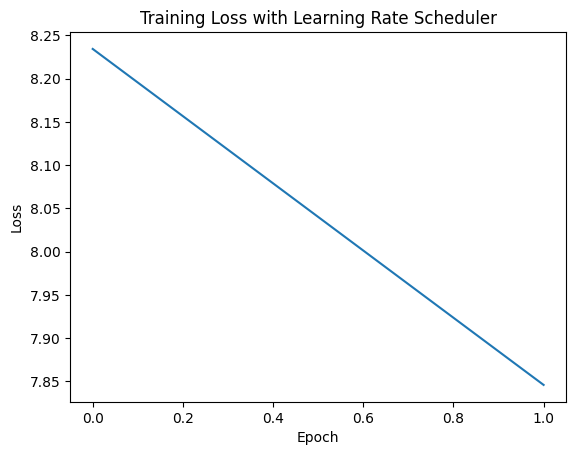

In [12]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Layer, Dense, LayerNormalization, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

def scheduler(epoch, lr):
    if epoch % 10 == 0 and epoch != 0:
        lr = lr * 0.5
    return lr
callback = tf.keras.callbacks.LearningRateScheduler(scheduler)
history = model.fit(X, Y, epochs=2, batch_size=64, callbacks=[callback])
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss with Learning Rate Scheduler')
plt.show()

<details>
    <summary>Click here for Solution</summary>

```python
# Write your code here
!pip install pandas
!pip install scikit-learn
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Layer, Dense, LayerNormalization, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Define a learning rate scheduler  
def scheduler(epoch, lr):  
    if epoch % 10 == 0 and epoch != 0:  
        lr = lr * 0.5  
    return lr  
 

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)  


# Train the model with the learning rate scheduler  
history = model.fit(X, Y, epochs=2, batch_size=64, callbacks=[callback])  
   

# Plot the training loss  
plt.plot(history.history['loss'])  
plt.xlabel('Epoch')  
plt.ylabel('Loss')  
plt.title('Training Loss with Learning Rate Scheduler')  
plt.show() 
```

</details>


### Exercise 3: Generate longer text sequences 

**Objective:** To explore the model's text generation capabilities and generate longer sequences. 

**Instructions:**

- Modify the `generate_text` function to generate 200 tokens instead of 100 

- Generate text using the trained model and the modified function 


In [13]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Layer, Dense, LayerNormalization, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

def generate_text(model, start_string, num_generate=200):
    input_eval = vectorizer([start_string]).numpy()
    input_eval = tf.convert_to_tensor(input_eval[:, -5:])
    text_generated = []
    for i in range(num_generate):
        predictions = model(input_eval)
        predictions = predictions[:, -1, :]
        predicted_id = tf.random.categorical(predictions, num_samples=1)[0, 0].numpy()
        input_eval = np.append(input_eval.numpy(), [[predicted_id]], axis=1)
        input_eval = input_eval[:, -5:]
        input_eval = tf.convert_to_tensor(input_eval)
        text_generated.append(vectorizer.get_vocabulary()[predicted_id])
    return start_string + ' ' + ' '.join(text_generated)
start_string = 'To be, or not to be'
generated_text = generate_text(model, start_string)
print(generated_text)

To be, or not to be fantastical bate left vastidity maket next noddle sweeting handled ghost worthily witht shorn learns proved relation month sirplague nobility refuse ever surge mutton period persuade misbegotten honour inform spirit sanctity sibyl arguing professes answer alliance cloud remainder melted stint celsa shoulderd wailing scratchd hastings nineteen palms clamour refined pout fortunate eat raze fell coral widest assistance avoided dam surety employd phaethon warder appointment thankless lastly poltroons prouds purchase abundant banishd undiscovered leadst articles meantime unactive shave appeared tickling mistresslet obscured pleasing verily opposite oftentimes material suitors plantagenet sip crimson pallabris quality retorts writ wooers dissemble europe potch ingratitude manes arts worthiest embassies wounds violently dozen peoples miscarry conclude untimely laughs egg overgone whether medicine stifled modesties blame grown sheer manner entertainment wait provision slaug

<details>
    <summary>Click here for Solution</summary>

```python

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Layer, Dense, LayerNormalization, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

def generate_text(model, start_string, num_generate=200):
    # Convert the start string to numbers (vectorize)
    input_eval = vectorizer([start_string]).numpy()

    # Ensure the input tensor has the correct shape
    input_eval = tf.convert_to_tensor(input_eval[:, -5:])  # Ensure it has a shape of (1, 5)
    
    text_generated = []

    for i in range(num_generate):
        # Make predictions using the model
        predictions = model(input_eval)

        # Ensure predictions is a matrix with shape [batch_size, num_classes]
        predictions = tf.squeeze(predictions, 0)  # Remove the batch dimension
        predictions = tf.expand_dims(predictions, 0)  # Add back a batch dimension for categorical
        
        # Use a categorical distribution to predict the next word
        predicted_id = tf.random.categorical(predictions, num_samples=1)[-1, 0].numpy()

        # Update the input tensor to include the predicted word, maintaining the sequence length
        input_eval = np.append(input_eval.numpy(), [[predicted_id]], axis=1)  # Append predicted token
        input_eval = input_eval[:, -5:]  # Keep only the last 5 tokens to match input shape
        input_eval = tf.convert_to_tensor(input_eval)  # Convert back to tensor
        
        # Add the predicted word to the generated text
        text_generated.append(vectorizer.get_vocabulary()[predicted_id])

    return start_string + ' ' + ' '.join(text_generated)


# Generate longer text
start_string = "To be, or not to be"
generated_text = generate_text(model, start_string)

print(generated_text)
```

</details>


#### Conclusion 

Congratulations on completing this lab! You have successfully built and trained a Transformer model for text generation in this lab using TensorFlow and Keras. You learned how to preprocess text data, create input and target sequences, define the Transformer model architecture, train the model, and generate text using the trained model. By completing this lab, you gained hands-on experience with Transformers for text generation and explored practical applications of this robust model architecture. 


Copyright © IBM Corporation. All rights reserved.
